# How we found it: a walkthrough of the four biggest findings

Every finding here followed the same loop:

1. **Ask a question** (from the data, or from something odd in an earlier result).
2. **Turn it into numbers**: a signal we can measure, and an outcome we care about.
3. **Compare groups** (rates, or AUC: how well a signal ranks risky people above safe ones; 0.5 = coin flip, 1.0 = perfect).
4. **Try to break it**: test on a later year it never saw, control for other factors, add confidence intervals, look for artifacts.
5. **Keep it only if it survives.**

The notebook recomputes everything from the raw CSVs, top to bottom. Runway always uses the README formula (`engine/core.py`).

In [1]:
import sys; sys.path.insert(0, '.')   # engine/ is vendored next to this notebook (README formulas)
import numpy as np, pandas as pd, matplotlib.pyplot as plt, matplotlib.ticker as mtick
import statsmodels.formula.api as smf
from sklearn.metrics import roc_auc_score
from engine.core import load, build_profiles, runway_value, runway_number, apply_shock, PRESETS
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 20)
%matplotlib inline

# chart style
SURFACE, INK, INK2, MUTED, GRID, BASE = '#fcfcfb', '#0b0b0b', '#52514e', '#898781', '#e1e0d9', '#c3c2b7'
BLUE, ORANGE, NEUTRAL = '#2a78d6', '#eb6834', '#c3c2b7'
plt.rcParams.update({'font.family': ['Helvetica Neue', 'Arial', 'DejaVu Sans'], 'font.size': 11,
    'axes.edgecolor': BASE, 'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'figure.dpi': 110})

def frame(ax, title, subtitle, grid='y'):
    ax.set_title(title, loc='left', fontsize=14, fontweight='bold', color=INK, pad=24)
    ax.text(0, 1.03, subtitle, transform=ax.transAxes, fontsize=10, color=INK2)
    for s in ['top', 'right', 'left']: ax.spines[s].set_visible(False)
    ax.grid(axis=grid, color=GRID, linewidth=0.8); ax.set_axisbelow(True); ax.tick_params(length=0)

def bars(ax, labels, values, fmt, colors=None):
    b = ax.bar(labels, values, color=colors or BLUE, width=0.55, edgecolor=SURFACE, linewidth=2)
    for r, v in zip(b, values):
        ax.text(r.get_x() + r.get_width()/2, r.get_height(), fmt(v), ha='center', va='bottom', fontsize=10, fontweight='bold', color=INK)

pct = lambda d=0: (lambda v: f'{v:.{d}%}')

## Step 0: the data
One row per customer per month (185,326 rows). The columns that matter most here: `money_in`, `money_out`, `min_balance` (lowest end-of-day balance that month), `avg_daily_balance`, `days_below_zero`, and the cost categories.

In [2]:
ms, loans = load('../data/data')
ms = ms.reset_index(drop=True)
print(f'{ms.account_id.nunique():,} accounts | {len(ms):,} account-months | {ms.month.min()} to {ms.month.max()} | {len(loans)} loans')
ms[['account_id','month','money_in','money_out','household_bills','cash_withdrawals_genuine','min_balance','avg_daily_balance','days_below_zero']].head()

4,500 accounts | 185,326 account-months | 2020-01 to 2025-12 | 682 loans


,account_id,month,money_in,money_out,household_bills,cash_withdrawals_genuine,min_balance,avg_daily_balance,days_below_zero
0,20111,2022-11,503.42,0.00,0.0,0.00,503.42,503.42,0.0
1,20111,2022-12,22132.18,4467.82,0.0,4467.82,503.42,16508.05,0.0
2,20111,2023-01,25433.96,12207.84,0.0,12207.84,18167.78,35404.34,0.0
3,20111,2023-02,130.45,7173.68,0.0,7173.68,24220.16,30886.10,0.0
4,20111,2023-03,130.45,5663.43,0.0,5663.43,18687.24,23624.11,0.0


---
# Finding 1: your worst day matters more than your average

**Step 1, the question.** The README's buffer is the *average* balance. Two people with the same average can live very differently: one steady, one swinging down to $50 every month. Does the low point carry information the average misses?

**Step 2, the signal.** For each loan, look at the borrower's 12 months **before** the loan was granted (so nothing after the decision leaks in), and take the lowest balance.

In [3]:
ms['m'] = pd.to_datetime(ms.month)
rows = []
for _, l in loans.iterrows():
    h = ms[(ms.account_id == l.account_id) & (ms.m < pd.Timestamp(l.loan_start).to_period('M').to_timestamp())].tail(12)
    if len(h) < 6: continue                      # need at least 6 months of history before the loan
    rows.append({'defaulted': l.defaulted, 'income': h.money_in.median(),
                 'income_vol': h.money_in.std() / max(h.money_in.mean(), 1),   # month-to-month swing
                 'worst_day': h.min_balance.min(),                              # the low point
                 'avg_buffer_months': h.avg_daily_balance.tail(6).mean() / max(h.money_out.median(), 1),
                 'payment_to_income': l.monthly_payment / max(h.money_in.median(), 1),
                 'loan_amount': l.amount})
LF = pd.DataFrame(rows)
print(f'{len(LF)} loans with >= 6 months of history, {int(LF.defaulted.sum())} defaulted ({LF.defaulted.mean():.1%})')
LF.head()

615 loans with >= 6 months of history, 65 defaulted (10.6%)


,defaulted,income,income_vol,worst_day,avg_buffer_months,payment_to_income,loan_amount
0,0,24779.960,0.962468,2830.52,1.019805,0.147643,175611.84
1,0,22249.885,0.459486,125.85,2.040660,0.165563,132615.00
2,0,5940.820,0.496025,629.27,2.912553,0.748452,213428.16
3,0,25381.575,0.186862,125.85,2.391342,0.078121,118969.80
4,0,12957.550,0.368854,503.42,2.035466,0.450090,279939.36


**Step 3, compare groups.** Split loans by the worst day and look at the default rate.

,default rate,loans
worst_band,,
Below $500,21.6%,204
$500-2k,10.8%,111
$2k-5k,16.7%,42
Above $5k,0.8%,258


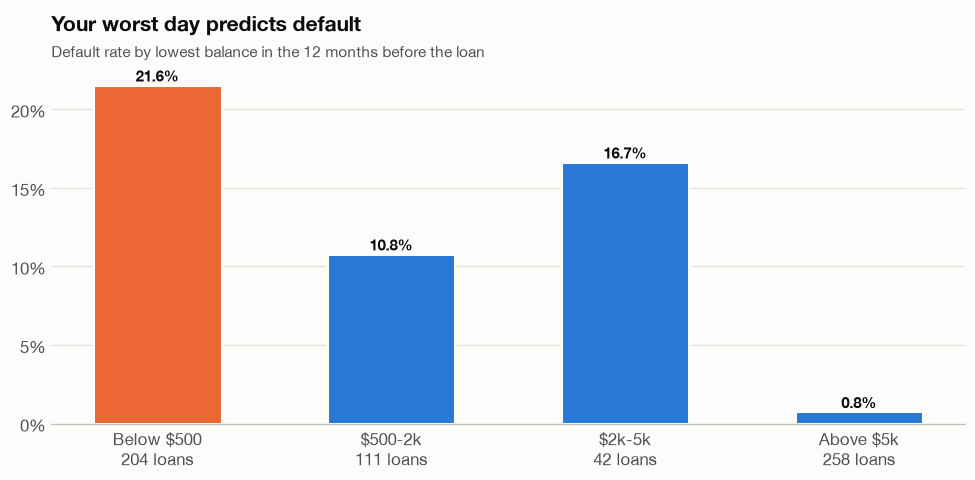

In [4]:
LF['worst_band'] = pd.cut(LF.worst_day, [-1e9, 500, 2000, 5000, 1e9], labels=['Below $500', '$500-2k', '$2k-5k', 'Above $5k'])
t = LF.groupby('worst_band', observed=True).defaulted.agg(['mean', 'size'])
display(t.rename(columns={'mean': 'default rate', 'size': 'loans'}).style.format({'default rate': '{:.1%}'}))
fig, ax = plt.subplots(figsize=(9, 4.5))
bars(ax, [f'{k}\n{n} loans' for k, n in zip(t.index.astype(str), t['size'])], t['mean'], pct(1), [ORANGE] + [BLUE]*3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
frame(ax, 'Your worst day predicts default', 'Default rate by lowest balance in the 12 months before the loan'); plt.tight_layout(); plt.show()

**Step 4, try to break it: predict the future.** Loans are only 615. A much bigger test: compute every customer's signals using **only data up to Dec 2024**, then check who was actually **overdrawn in 2025**. The signal never sees the answer.

In [5]:
past, fut = ms[ms.month <= '2024-12'], ms[ms.month >= '2025-01']
gp = past.groupby('account_id'); last12 = gp.tail(12).groupby('account_id')
V = pd.DataFrame({'I': gp.money_in.median(), 'S': gp.money_out.median(), 'n_past': gp.size(),
                  'B': gp.tail(6).groupby('account_id').avg_daily_balance.mean(),
                  'worst_day': last12.min_balance.min(),
                  'income_vol': (last12.money_in.std() / last12.money_in.mean().where(lambda s: s > 0)).fillna(0),
                  'overdrawn_before': gp.days_below_zero.sum() > 0})
gf = fut.groupby('account_id')
V['fut_months'] = gf.size(); V['overdrawn_2025'] = gf.days_below_zero.sum() > 0
V = V[(V.n_past >= 12) & (V.fut_months >= 6)].copy()
V['overdrawn_2025'] = V.overdrawn_2025.astype(bool)
V['runway_today'] = [runway_number(runway_value(r.I, r.S, r.B)) for r in V.itertuples()]
V['runway_laid_off'] = [runway_number(runway_value(0.55 * r.I, r.S, r.B)) for r in V.itertuples()]
V['savings_months'] = (V.B / V.S.where(V.S > 0)).fillna(1e6)
print(f'{len(V):,} accounts | overdrawn in 2025: {V.overdrawn_2025.sum()} ({V.overdrawn_2025.mean():.1%})')

3,657 accounts | overdrawn in 2025: 129 (3.5%)


**Step 5, compare every signal on the same test** (AUC with a 95% bootstrap interval: resample the accounts 1,000 times and see how much the score moves).

,AUC,low,high
signal,,,
Lowest balance (worst day),0.897,0.865,0.927
"Savings, months of spending",0.785,0.731,0.830
Runway if laid off,0.782,0.731,0.825
Overdrawn before 2025,0.757,0.713,0.805
Income volatility,0.734,0.693,0.775
Runway today,0.671,0.622,0.719
Income level,0.452,0.401,0.500


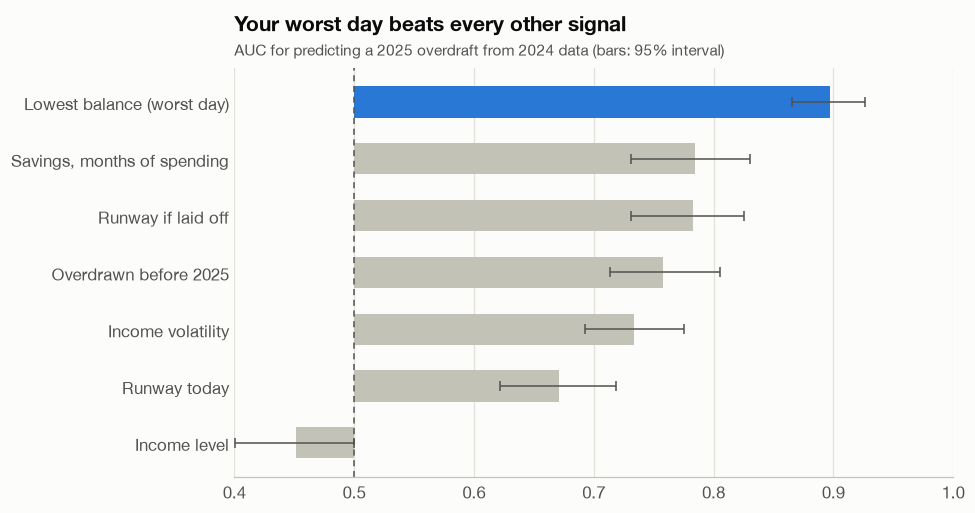

In [6]:
def auc_ci(y, s, n=1000, seed=0):
    y, s, rng = np.asarray(y), np.asarray(s), np.random.default_rng(seed)
    a = [roc_auc_score(y[i], s[i]) for i in (rng.integers(0, len(y), len(y)) for _ in range(n)) if y[i].min() != y[i].max()]
    return roc_auc_score(y, s), *np.percentile(a, [2.5, 97.5])

signals = {'Lowest balance (worst day)': -V.worst_day, 'Savings, months of spending': -V.savings_months,
           'Runway if laid off': -V.runway_laid_off, 'Overdrawn before 2025': V.overdrawn_before.astype(int),
           'Income volatility': V.income_vol, 'Runway today': -V.runway_today, 'Income level': -V.I}
res = pd.DataFrame([(k, *auc_ci(V.overdrawn_2025, s)) for k, s in signals.items()], columns=['signal', 'AUC', 'low', 'high']).set_index('signal')
display(res.round(3))
fig, ax = plt.subplots(figsize=(9, 4.8)); r = res.iloc[::-1]
ax.barh(r.index, r.AUC - 0.5, left=0.5, color=[BLUE if k.startswith('Lowest') else NEUTRAL for k in r.index], height=0.55)
ax.errorbar(r.AUC, range(len(r)), xerr=[r.AUC - r.low, r.high - r.AUC], fmt='none', ecolor=INK2, capsize=3, linewidth=1)
ax.axvline(0.5, color=INK2, linestyle=(0, (4, 3)), linewidth=1); ax.set_xlim(0.4, 1)
frame(ax, 'Your worst day beats every other signal', 'AUC for predicting a 2025 overdraft from 2024 data (bars: 95% interval)', grid='x'); plt.tight_layout(); plt.show()

**Step 6, try to break it again.** Objection: *"Of course people who were already overdrawn get overdrawn again."* So repeat the test on **only** the customers who had **never** been overdrawn before 2025.

In [7]:
N = V[~V.overdrawn_before]
print(f'{len(N):,} never-overdrawn accounts; {N.overdrawn_2025.sum()} became overdrawn in 2025')
for k in ['Lowest balance (worst day)', 'Income volatility', 'Runway if laid off', 'Income level']:
    s = signals[k].loc[N.index]; a, lo, hi = auc_ci(N.overdrawn_2025, s)
    print(f'  {k:28s} AUC {a:.2f}  [{lo:.2f}, {hi:.2f}]')

3,461 never-overdrawn accounts; 58 became overdrawn in 2025


  Lowest balance (worst day)   AUC 0.81  [0.75, 0.86]


  Income volatility            AUC 0.75  [0.68, 0.81]


  Runway if laid off           AUC 0.68  [0.60, 0.76]


  Income level                 AUC 0.48  [0.40, 0.56]


**Verdict: kept.** The worst day is the strongest signal (AUC about 0.90), still strong for people never overdrawn before (about 0.81), and income level is no better than a coin flip.
*Caveat:* partly mechanical (a balance near $0 is close to negative), which is exactly why Step 6 matters.

---
# Finding 2: higher earners are less likely to survive a job loss

**Step 1, the question.** Who survives the README's main scenario (laid off, EI pays 55%, 6 months)? We expected high earners to be safest.

**Step 2, the signal.** Run the README formula for every customer under that shock; "survives" = runway of 6 months or more.

In [8]:
prof = build_profiles(ms.drop(columns=['m']), loans)
prof['ei_runway'] = [runway_number(apply_shock(p, PRESETS['job_loss_ei'])['runway_after']) for _, p in prof.iterrows()]
prof['survives'] = prof.ei_runway >= 6
g = ms.groupby('account_id')
prof['retiree'] = (g.pension_in.sum() / g.money_in.sum()).reindex(prof.index) > 0.5   # a job loss can't cut a pension
prof['savings_months'] = prof.B_buffer / prof.S_spending.where(prof.S_spending > 0)
print(f'All customers: {prof.survives.mean():.1%} survive; retirees excluded from here on ({prof.retiree.sum()} of them)')
W = prof[~prof.retiree].copy()
W['income_group'] = pd.qcut(W.I_income, 4, labels=['Lowest 25%', '2nd', '3rd', 'Highest 25%'])
W.groupby('income_group', observed=True).agg(median_income=('I_income','median'), savings_months=('savings_months','median'), survives=('survives','mean')).round(2)

All customers: 64.9% survive; retirees excluded from here on (740 of them)


,median_income,savings_months,survives
income_group,,,
Lowest 25%,2084.77,8.31,0.92
2nd,7096.36,3.29,0.62
3rd,11992.03,2.50,0.49
Highest 25%,19704.87,1.81,0.30


**Step 3, something looks off.** The lowest group survives at about 92%, which is suspiciously high. How can people with the least income have the most months of savings? Look closer.

In [9]:
low = W[W.income_group == 'Lowest 25%']
side = low.savings_months.isna() | (low.savings_months > 12)   # NaN = no spending at all
print(f"Lowest group: {side.mean():.0%} either spend nothing or hold more than 12 months of their own spending in savings")
print('That looks like side accounts: money parked here, salary paid somewhere else. Remove them and re-check.')

Lowest group: 29% either spend nothing or hold more than 12 months of their own spending in savings
That looks like side accounts: money parked here, salary paid somewhere else. Remove them and re-check.


**Step 4, try to break it: remove the suspicious accounts.**

,median_income,savings_months,hit_size,survives
income_group,,,,
Lowest 25%,2390.47,6.58,0.35,0.85
2nd,7960.92,2.92,0.43,0.56
3rd,12505.16,2.48,0.44,0.48
Highest 25%,20351.10,1.79,0.42,0.29


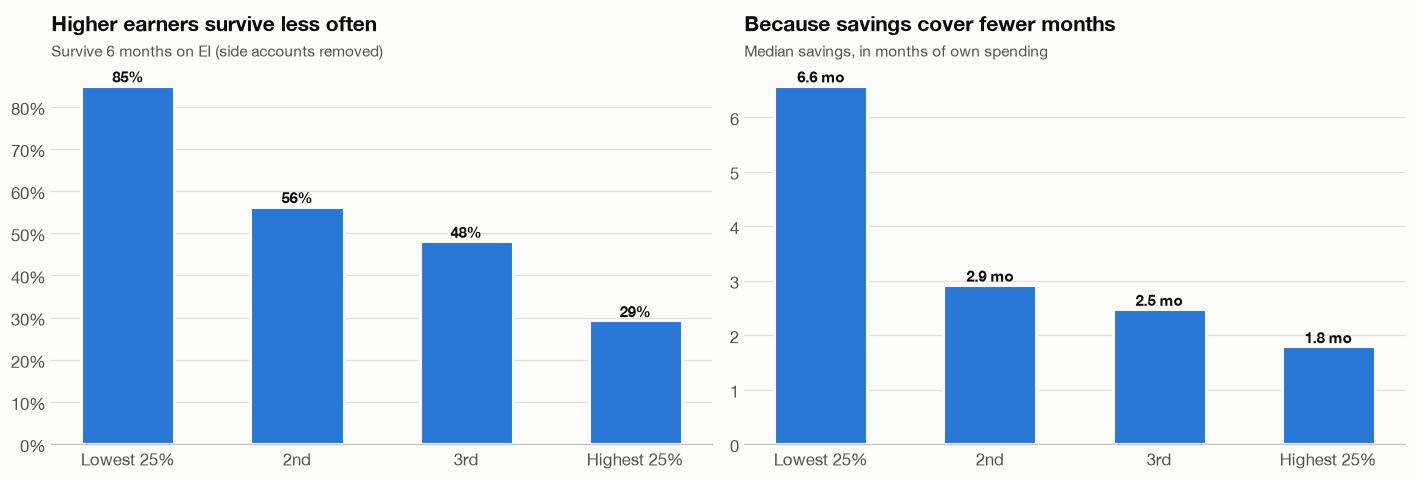

In [10]:
W2 = W[W.savings_months < 12].copy()
W2['income_group'] = pd.qcut(W2.I_income, 4, labels=['Lowest 25%', '2nd', '3rd', 'Highest 25%'])
W2['gap_share'] = (W2.S_spending - 0.55 * W2.I_income).clip(lower=0) / W2.S_spending   # how big the hit is, relative to spending
t = W2.groupby('income_group', observed=True).agg(median_income=('I_income','median'), savings_months=('savings_months','median'),
                                                   hit_size=('gap_share','median'), survives=('survives','mean'))
display(t.round(2))
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
bars(axes[0], t.index.astype(str), t.survives, pct(0)); axes[0].yaxis.set_major_formatter(mtick.PercentFormatter(1.0))
frame(axes[0], 'Higher earners survive less often', 'Survive 6 months on EI (side accounts removed)')
bars(axes[1], t.index.astype(str), t.savings_months, lambda v: f'{v:.1f} mo')
frame(axes[1], 'Because savings cover fewer months', 'Median savings, in months of own spending'); plt.tight_layout(); plt.show()

**Step 5, why.** The `hit_size` column shows the shock is about the same relative size for everyone (a gap of roughly 42% of spending). What changes is savings: they cover 2.9 months for the 2nd group and only 1.8 for the top. **Spending grows faster than savings.**

**Verdict: kept,** with the side-account caveat stated.

---
# Finding 3: two warning signs predict default, and income isn't one

**Step 1, the question.** Among the 615 loans, what did defaulters look like **before** the loan?

**Step 2, a simple comparison.** Split by income level and by steadiness (unsteady = income varies by 50% or more of its average).

In [11]:
LF['level'] = np.where(LF.income > LF.income.median(), 'Higher income', 'Lower income')
LF['unsteady'] = (LF.income_vol >= 0.5).astype(int)
t = LF.groupby(['level', 'unsteady']).defaulted.mean().unstack().loc[['Lower income', 'Higher income']]
t.columns = ['Steady', 'Unsteady']; display(t.style.format('{:.1%}'))

,Steady,Unsteady
level,,
Lower income,5.5%,27.1%
Higher income,2.5%,14.0%


**Step 3, try to break it: control for everything else.** Maybe unsteady people also have less savings, or bigger loans. A logistic regression measures each factor **while holding the others fixed**. Results are odds ratios: 1 = no effect, 4.7 = odds of default 4.7 times higher.

,odds ratio,low 95%,high 95%,p-value
unsteady,4.666,2.466,8.828,0.000
dip_below_500,4.874,2.716,8.747,0.000
log_income,0.760,0.530,1.090,0.136
avg_buffer_months,1.000,1.000,1.000,0.480
payment_to_income,0.968,0.875,1.070,0.522
log_loan,2.251,1.476,3.432,0.000


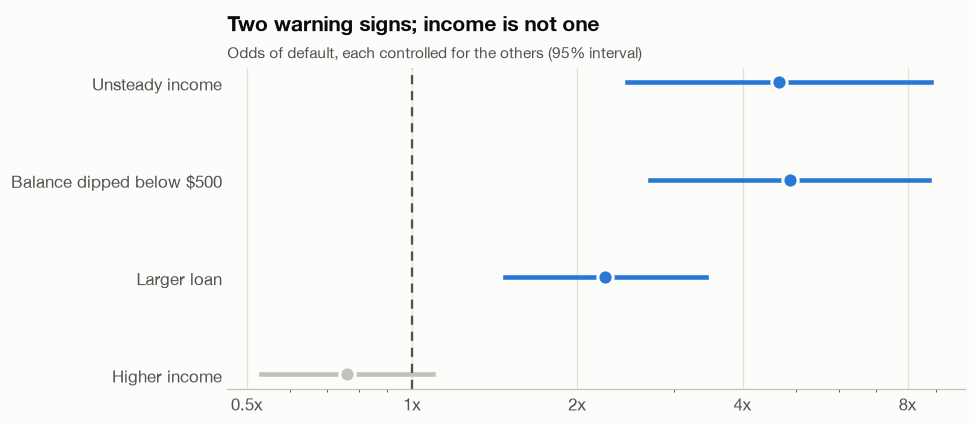

In [12]:
LF['dip_below_500'] = (LF.worst_day < 500).astype(int)
LF['log_income'] = np.log(LF.income.clip(lower=100)); LF['log_loan'] = np.log(LF.loan_amount)
model = smf.logit('defaulted ~ unsteady + dip_below_500 + log_income + avg_buffer_months + payment_to_income + log_loan', data=LF).fit(disp=0)
OR = pd.DataFrame({'odds ratio': np.exp(model.params), 'low 95%': np.exp(model.conf_int()[0]),
                   'high 95%': np.exp(model.conf_int()[1]), 'p-value': model.pvalues}).drop('Intercept')
display(OR.round(3))
rows = [('Unsteady income', 'unsteady'), ('Balance dipped below $500', 'dip_below_500'), ('Larger loan', 'log_loan'), ('Higher income', 'log_income')]
fig, ax = plt.subplots(figsize=(9, 4))
for i, (lab, k) in enumerate(rows[::-1]):
    c = BLUE if OR.loc[k, 'p-value'] < 0.05 else NEUTRAL
    ax.plot([OR.loc[k, 'low 95%'], OR.loc[k, 'high 95%']], [i, i], color=c, linewidth=3)
    ax.plot(OR.loc[k, 'odds ratio'], i, 'o', color=c, markersize=10, markeredgecolor=SURFACE, markeredgewidth=2)
ax.set_yticks(range(len(rows)), [r[0] for r in rows[::-1]]); ax.set_xscale('log')
ax.set_xticks([0.5, 1, 2, 4, 8], ['0.5x', '1x', '2x', '4x', '8x']); ax.axvline(1, color=INK2, linestyle=(0, (4, 3)))
frame(ax, 'Two warning signs; income is not one', 'Odds of default, each controlled for the others (95% interval)', grid='x'); plt.tight_layout(); plt.show()

**Verdict: kept.** Unsteady income (about 4.7x) and a dip below $500 (about 4.9x) each raise the odds of default *independently*; income level is not significant.
*Caveat:* only 65 defaults, so the exact multipliers are rough; the direction is solid.

---
# Finding 4: the stress test really works, and a near-miss gives a year's warning

**Step 1, the question.** Our tool's core number is "runway if laid off". Does it predict anything **real**?

**Step 2, test the tool itself.** Reuse the 2024 to 2025 setup from Finding 1: bucket customers by their 2024 runway-if-laid-off and look at real 2025 overdrafts.

,mean,size
band,,
Under 3 mo,0.176812,345
3-6 mo,0.036644,1037
6-12 mo,0.016949,885
12+ mo,0.010791,1390


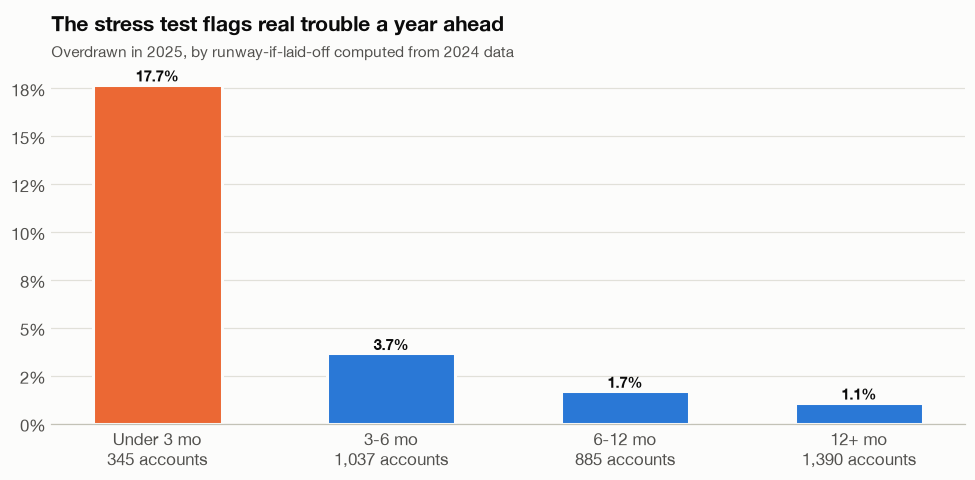

In [13]:
V['band'] = pd.cut(V.runway_laid_off, [-0.1, 3, 6, 12, 1e9], labels=['Under 3 mo', '3-6 mo', '6-12 mo', '12+ mo'])
t = V.groupby('band', observed=True).overdrawn_2025.agg(['mean', 'size']); display(t)
fig, ax = plt.subplots(figsize=(9, 4.5))
bars(ax, [f'{k}\n{n:,} accounts' for k, n in zip(t.index, t['size'])], t['mean'], pct(1), [ORANGE] + [BLUE]*3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
frame(ax, 'The stress test flags real trouble a year ahead', 'Overdrawn in 2025, by runway-if-laid-off computed from 2024 data'); plt.tight_layout(); plt.show()

**Step 3, real shocks instead of the formula.** Search the data for customers whose income **actually** collapsed: 3 months in a row at 50% or less of their usual (median of the prior 12 months). These are real versions of the judges' twist cards.

569 real income crashes; median income drop 86%; overdrawn within 6 months: 8.6%


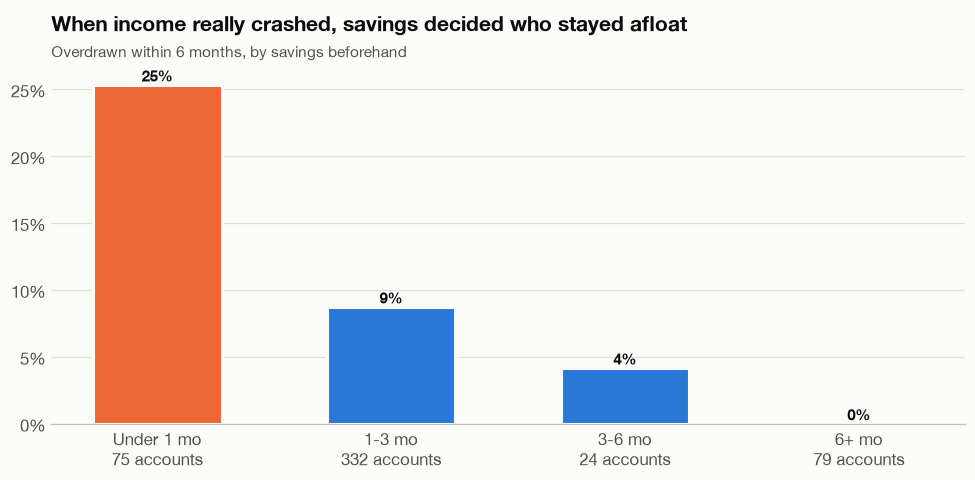

In [14]:
crashes = []
for acc, g in ms.groupby('account_id'):
    g = g.reset_index(drop=True)
    for i in range(12, len(g) - 3):
        usual = g.money_in.iloc[i-12:i].median()
        if usual > 0 and (g.money_in.iloc[i:i+3] <= 0.5 * usual).all():
            pre, post = g.iloc[i-12:i], g.iloc[i:i+6]
            S = pre.money_out.median()
            crashes.append({'account_id': acc, 'start': g.month.iloc[i], 'start_idx': i, 'drop': 1 - g.money_in.iloc[i:i+3].mean() / usual,
                            'savings_months': pre.avg_daily_balance.tail(6).mean() / S if S > 0 else np.nan,
                            'overdrawn_within_6m': post.days_below_zero.sum() > 0})
            break   # first crash per account
CR = pd.DataFrame(crashes)
print(f'{len(CR)} real income crashes; median income drop {CR["drop"].median():.0%}; overdrawn within 6 months: {CR.overdrawn_within_6m.mean():.1%}')
CR['band'] = pd.cut(CR.savings_months, [-1e9, 1, 3, 6, 1e9], labels=['Under 1 mo', '1-3 mo', '3-6 mo', '6+ mo'])
t = CR.groupby('band', observed=True).overdrawn_within_6m.agg(['mean', 'size'])
fig, ax = plt.subplots(figsize=(9, 4.5))
bars(ax, [f'{k}\n{n} accounts' for k, n in zip(t.index, t['size'])], t['mean'], pct(0), [ORANGE] + [BLUE]*3)
ax.yaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
frame(ax, 'When income really crashed, savings decided who stayed afloat', 'Overdrawn within 6 months, by savings beforehand'); plt.tight_layout(); plt.show()

**Step 4, what did people actually cut?** Compare each cost category in the 3 months after the crash with its usual level.

,median change,accounts
Cash withdrawals,-59%,504
Household bills,+0%,204
Loan payments,+0%,69
Insurance,+0%,40
Other transfers out,+0%,91


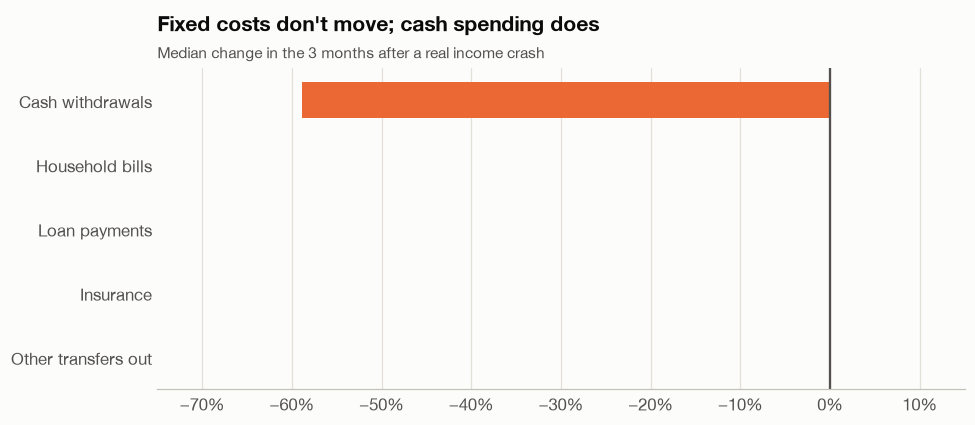

In [15]:
cats = {'Cash withdrawals': 'cash_withdrawals_genuine', 'Household bills': 'household_bills', 'Loan payments': 'loan_payments',
        'Insurance': 'insurance', 'Other transfers out': 'transfers_out_other'}
by_acc = {a: g.reset_index(drop=True) for a, g in ms[ms.account_id.isin(CR.account_id)].groupby('account_id')}
chg = {}
for lab, col in cats.items():
    vals = []
    for r in CR.itertuples():
        g = by_acc[r.account_id]; usual = g[col].iloc[r.start_idx-12:r.start_idx].median()
        if usual > 0: vals.append(g[col].iloc[r.start_idx:r.start_idx+3].mean() / usual - 1)
    chg[lab] = (np.median(vals), len(vals))
t = pd.DataFrame(chg, index=['median change', 'accounts']).T; display(t.style.format({'median change': '{:+.0%}', 'accounts': '{:.0f}'}))
fig, ax = plt.subplots(figsize=(9, 4)); r = t.iloc[::-1]
ax.barh(r.index, r['median change'], color=[ORANGE if v < -0.05 else NEUTRAL for v in r['median change']], height=0.55)
ax.axvline(0, color=INK2); ax.set_xlim(-0.75, 0.15); ax.xaxis.set_major_formatter(mtick.PercentFormatter(1.0, decimals=0))
frame(ax, "Fixed costs don't move; cash spending does", 'Median change in the 3 months after a real income crash', grid='x'); plt.tight_layout(); plt.show()

**Step 5, how much warning is there?** For everyone ever overdrawn, look back for the first near-miss (a month whose lowest balance was between $0 and $500) and count the months in between.

288 accounts ever overdrawn; 64% had a near-miss first; median warning 13 months (middle half 8-21)


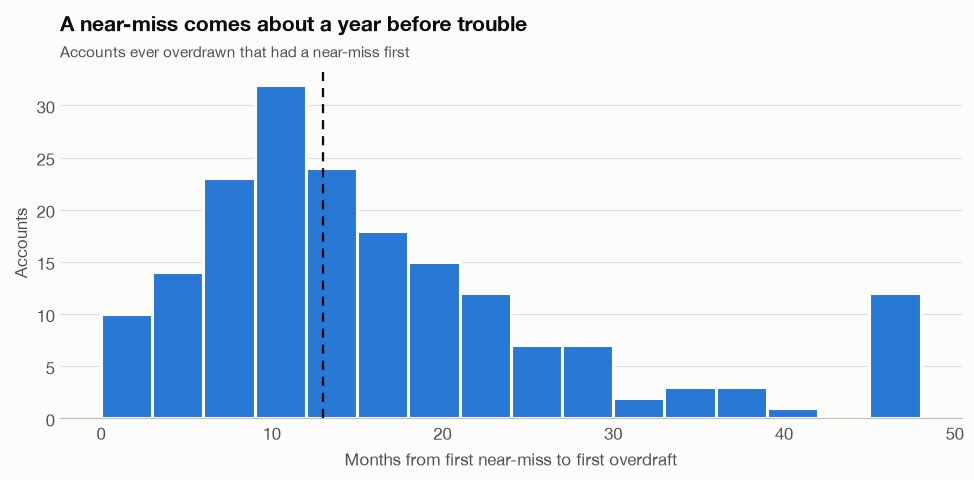

In [16]:
lead = []
for acc, g in ms.groupby('account_id'):
    neg = g.index[g.days_below_zero > 0]
    if len(neg) == 0: continue
    before = g.loc[:neg[0] - 1]; near = before.index[(before.min_balance >= 0) & (before.min_balance < 500)]
    lead.append(g.index.get_loc(neg[0]) - g.index.get_loc(near[0]) if len(near) else np.nan)
lead = pd.Series(lead)
print(f'{len(lead)} accounts ever overdrawn; {lead.notna().mean():.0%} had a near-miss first; median warning {lead.median():.0f} months (middle half {lead.quantile(.25):.0f}-{lead.quantile(.75):.0f})')
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.hist(lead.dropna().clip(upper=47), bins=np.arange(0, 49, 3), color=BLUE, edgecolor=SURFACE, linewidth=2)
ax.axvline(lead.median(), color=INK, linestyle=(0, (4, 3))); ax.set_xlabel('Months from first near-miss to first overdraft'); ax.set_ylabel('Accounts')
frame(ax, 'A near-miss comes about a year before trouble', 'Accounts ever overdrawn that had a near-miss first'); plt.tight_layout(); plt.show()

**Verdict: kept.** The 2024 stress test separates 17.7% from 1.1% real 2025 overdrafts; in real crashes savings decided who stayed afloat; fixed costs didn't move; a near-miss came a median 13 months before the first overdraft.
*Caveat:* in cash-heavy data, part of the cash-spending cut may simply be less cash coming in.

---
# One that did NOT survive: "income crashes cluster in January"

The first list of crashes (Step 3 above) had many starting in January. Before claiming it, check the **base rate**: how often is *any* month a low-income month?

In [17]:
print('January share among detected crashes:', f"{(CR.start.str[5:] == '01').mean():.0%}")
ms['mon'] = ms.month.str[5:]
low = ms.money_in < 0.5 * ms.groupby('account_id').money_in.transform('median')
print('Share of low-income months, by calendar month:'); print(low.groupby(ms.mon).mean().round(3).to_dict())

January share among detected crashes: 19%
Share of low-income months, by calendar month:
{'01': 0.078, '02': 0.085, '03': 0.077, '04': 0.08, '05': 0.081, '06': 0.078, '07': 0.078, '08': 0.084, '09': 0.08, '10': 0.078, '11': 0.084, '12': 0.079}


Low-income months are equally common in every month (about 8%), so the January pile-up came from *how the first crash per account was picked*, not from real seasonality. **Withdrawn.** (January *spending* really is higher; that is a separate result and still stands.)

---
# Summary

| Finding | Test that it survived |
|---|---|
| Worst day predicts trouble (AUC about 0.90) | Predicting 2025 from 2024; customers never overdrawn before |
| Higher earners survive a job loss less often | Removing side-account-like customers; same relative hit for everyone |
| Unsteady income and a dip below $500 each about 5x the odds of default; income not significant | Regression controlling for income, savings, loan size, payment burden |
| The stress test predicts real trouble; a near-miss gives about a year's warning | Out-of-time test; 569 real income crashes |
| ~~Crashes cluster in January~~ | Failed the base-rate check, withdrawn |